In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42

In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00229/Skin_NonSkin.txt"

df = pd.read_csv(
    url,
    sep=r"\s+",
    header=None,
    names=["B", "G", "R", "Target"]
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (245057, 4)


,B,G,R,Target
0,74,85,123,1
1,73,84,122,1
2,72,83,121,1
3,70,81,119,1
4,70,81,119,1


In [ ]:
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nClass distribution:")
print(df["Target"].value_counts())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 245057 entries, 0 to 245056
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   B       245057 non-null  int64
 1   G       245057 non-null  int64
 2   R       245057 non-null  int64
 3   Target  245057 non-null  int64
dtypes: int64(4)
memory usage: 7.5 MB

Statistical summary:


,B,G,R,Target
count,245057.000000,245057.000000,245057.000000,245057.000000
mean,125.065446,132.507327,123.177151,1.792461
std,62.255653,59.941197,72.562165,0.405546
min,0.000000,0.000000,0.000000,1.000000
25%,68.000000,87.000000,70.000000,2.000000
50%,139.000000,153.000000,128.000000,2.000000
75%,176.000000,177.000000,164.000000,2.000000
max,255.000000,255.000000,255.000000,2.000000



Missing values:
B         0
G         0
R         0
Target    0
dtype: int64

Duplicate rows:
193613

Class distribution:
Target
2    194198
1     50859
Name: count, dtype: int64


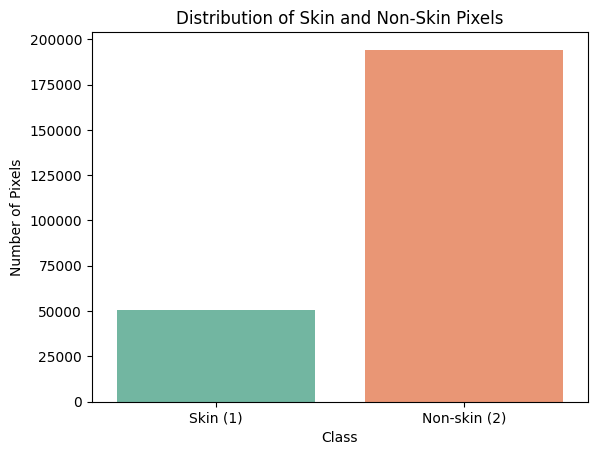

In [ ]:
sns.countplot(
    data=df,
    x="Target",
    hue="Target",
    palette="Set2",
    legend=False
)

plt.xticks([0, 1], ["Skin (1)", "Non-skin (2)"])
plt.title("Distribution of Skin and Non-Skin Pixels")
plt.xlabel("Class")
plt.ylabel("Number of Pixels")
plt.show()

In [ ]:
# Check whether identical BGR combinations have different labels

rgb_label_check = (
    df.groupby(["B", "G", "R"])["Target"]
    .nunique()
)

conflicting_pixels = rgb_label_check[rgb_label_check > 1]

print("Unique BGR combinations:", len(rgb_label_check))

print("BGR combinations with conflicting labels:",
      len(conflicting_pixels))

Unique BGR combinations: 51433
BGR combinations with conflicting labels: 11


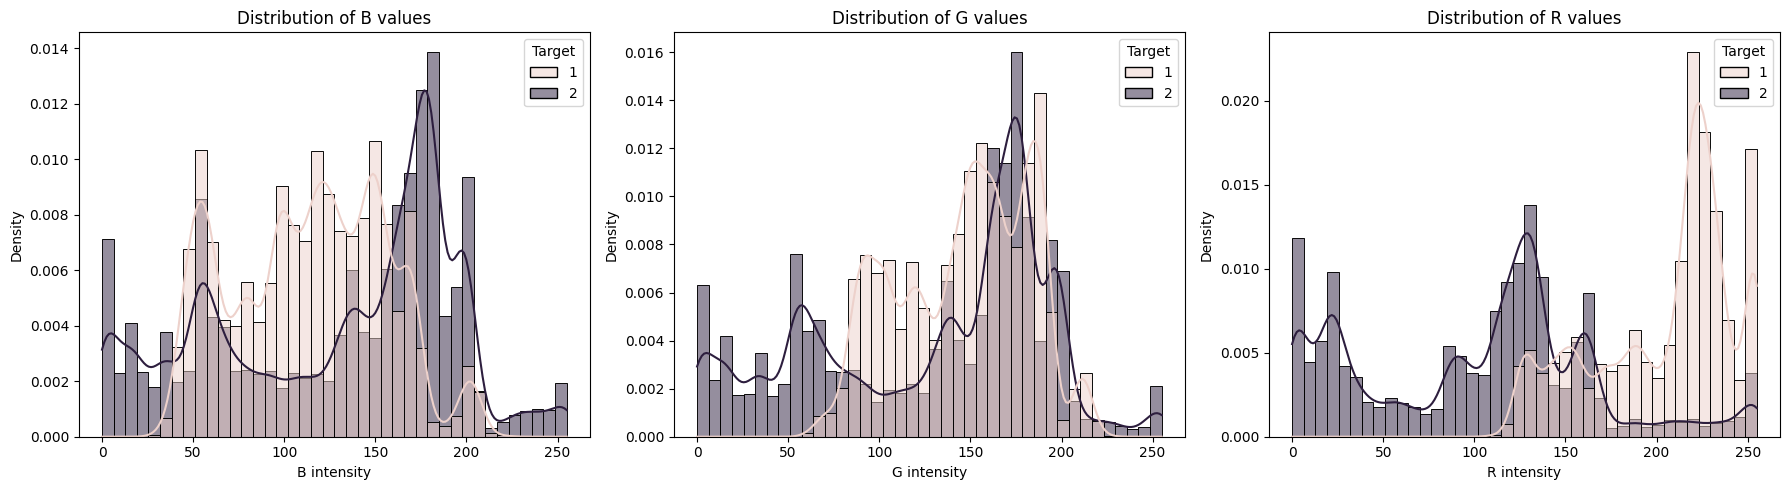

In [ ]:
# Distribution of individual color channels

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

features = ["B", "G", "R"]

for i, feature in enumerate(features):
    sns.histplot(
        data=df,
        x=feature,
        hue="Target",
        bins=40,
        kde=True,
        stat="density",
        common_norm=False,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {feature} values")
    axes[i].set_xlabel(f"{feature} intensity")

plt.tight_layout()
plt.show()

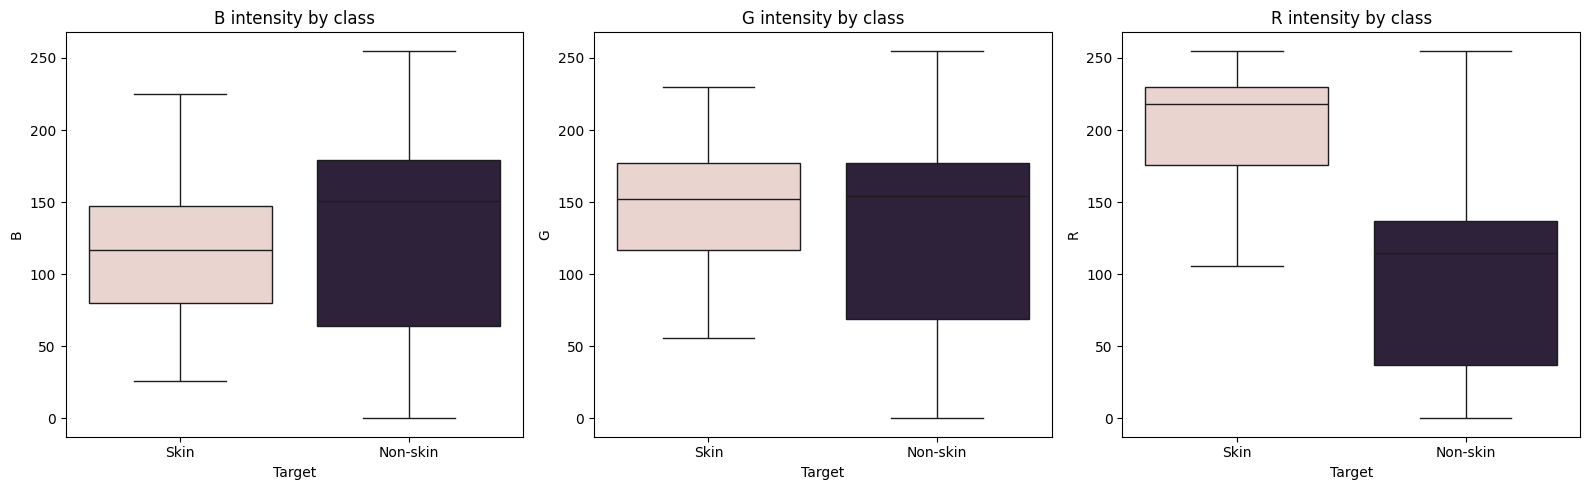

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, feature in enumerate(["B", "G", "R"]):
    sns.boxplot(
        data=df,
        x="Target",
        y=feature,
        hue="Target",
        legend=False,
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} intensity by class")
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(["Skin", "Non-skin"])

plt.tight_layout()
plt.show()

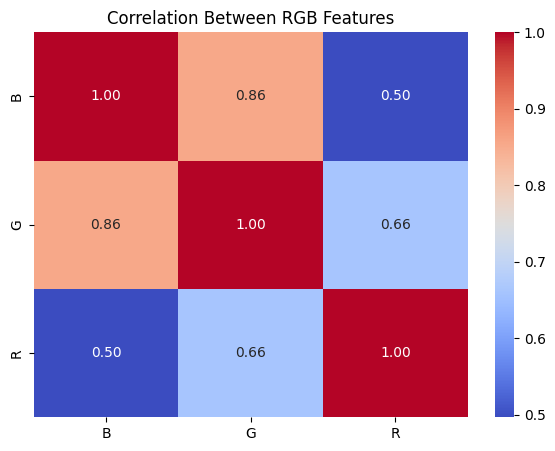

In [ ]:
plt.figure(figsize=(7, 5))

correlation = df[["B", "G", "R"]].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between RGB Features")
plt.show()

phase 2

In [ ]:
# Separate features and target

X = df[["B", "G", "R"]]

y = df["Target"].map({
    1: 1,  # Skin
    2: 0   # Non-skin
})

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (245057, 3)
Target shape: (245057,)

Target distribution:
Target
0    194198
1     50859
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

# Group identical BGR combinations together
groups = df.groupby(["B", "G", "R"], sort=False).ngroup()

# Create a stratified, group-aware split
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    sgkf.split(X, y, groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training features: (196319, 3)
Testing features: (48738, 3)

Training class distribution:
Target
0    79.348917
1    20.651083
Name: proportion, dtype: float64

Testing class distribution:
Target
0    78.831712
1    21.168288
Name: proportion, dtype: float64


In [ ]:
train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])

print("Overlapping BGR groups:",
      len(train_groups.intersection(test_groups)))

Overlapping BGR groups: 0


In [ ]:
from sklearn.preprocessing import StandardScaler

# Initialize scaler
scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data
X_test_scaled = scaler.transform(X_test)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

Scaled training data: (196319, 3)
Scaled testing data: (48738, 3)


In [ ]:
print("PREPROCESSING SUMMARY")
print("-" * 40)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nSkin samples in training:", (y_train == 1).sum())
print("Non-skin samples in training:", (y_train == 0).sum())

print("\nSkin samples in testing:", (y_test == 1).sum())
print("Non-skin samples in testing:", (y_test == 0).sum())

print("\nMissing values in training:", X_train.isnull().sum().sum())
print("Missing values in testing:", X_test.isnull().sum().sum())

PREPROCESSING SUMMARY
----------------------------------------
Training samples: 196319
Testing samples: 48738

Skin samples in training: 40542
Non-skin samples in training: 155777

Skin samples in testing: 10317
Non-skin samples in testing: 38421

Missing values in training: 0
Missing values in testing: 0


phase 3

In [ ]:
import time

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        algorithm="kd_tree",
        n_jobs=-1
    )
}

In [ ]:
results = []
trained_models = {}
predictions = {}
probabilities = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    # Select scaled or original features
    if name in ["Logistic Regression", "KNN"]:
        Xtr = X_train_scaled
        Xte = X_test_scaled
    else:
        Xtr = X_train
        Xte = X_test

    # Training
    start_time = time.perf_counter()
    model.fit(Xtr, y_train)
    training_time = time.perf_counter() - start_time

    # Prediction
    start_time = time.perf_counter()
    y_pred = model.predict(Xte)
    prediction_time = time.perf_counter() - start_time

    # Predicted probabilities
    y_prob = model.predict_proba(Xte)[:, 1]

    # Evaluation
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, pos_label=1)
    recall = recall_score(y_test, y_pred, pos_label=1)
    f1 = f1_score(y_test, y_pred, pos_label=1)

    # Store results
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time
    })

    trained_models[name] = model
    predictions[name] = y_pred
    probabilities[name] = y_prob

    print(f"{name} completed!")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"Training time: {training_time:.3f} seconds")
    print(f"Prediction time: {prediction_time:.3f} seconds")


Training Logistic Regression...
Logistic Regression completed!
Accuracy: 0.9185
Precision: 0.7877
Recall: 0.8421
F1-score: 0.8140
Training time: 0.300 seconds
Prediction time: 0.001 seconds

Training Decision Tree...
Decision Tree completed!
Accuracy: 0.9991
Precision: 0.9968
Recall: 0.9988
F1-score: 0.9978
Training time: 0.479 seconds
Prediction time: 0.003 seconds

Training KNN...
KNN completed!
Accuracy: 0.9993
Precision: 0.9969
Recall: 0.9998
F1-score: 0.9984
Training time: 0.318 seconds
Prediction time: 0.643 seconds


In [ ]:
baseline_results = pd.DataFrame(results)

baseline_results

,Model,Accuracy,Precision,Recall,F1-Score,Training Time (s),Prediction Time (s)
0,Logistic Regression,0.918544,0.787741,0.842105,0.814017,0.299558,0.000762
1,Decision Tree,0.999077,0.996808,0.998837,0.997821,0.479254,0.003289
2,KNN,0.999302,0.996907,0.999806,0.998355,0.317724,0.642725


In [ ]:
display(
    baseline_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "Training Time (s)": "{:.3f}",
        "Prediction Time (s)": "{:.3f}"
    })
)

,Model,Accuracy,Precision,Recall,F1-Score,Training Time (s),Prediction Time (s)
0,Logistic Regression,0.9185,0.7877,0.8421,0.8140,0.300,0.001
1,Decision Tree,0.9991,0.9968,0.9988,0.9978,0.479,0.003
2,KNN,0.9993,0.9969,0.9998,0.9984,0.318,0.643


In [ ]:
for name in models.keys():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            predictions[name],
            labels=[0, 1],
            target_names=["Non-skin", "Skin"],
            digits=4
        )
    )


Logistic Regression
              precision    recall  f1-score   support

    Non-skin     0.9568    0.9391    0.9479     38421
        Skin     0.7877    0.8421    0.8140     10317

    accuracy                         0.9185     48738
   macro avg     0.8723    0.8906    0.8809     48738
weighted avg     0.9210    0.9185    0.9195     48738


Decision Tree
              precision    recall  f1-score   support

    Non-skin     0.9997    0.9991    0.9994     38421
        Skin     0.9968    0.9988    0.9978     10317

    accuracy                         0.9991     48738
   macro avg     0.9982    0.9990    0.9986     48738
weighted avg     0.9991    0.9991    0.9991     48738


KNN
              precision    recall  f1-score   support

    Non-skin     0.9999    0.9992    0.9996     38421
        Skin     0.9969    0.9998    0.9984     10317

    accuracy                         0.9993     48738
   macro avg     0.9984    0.9995    0.9990     48738
weighted avg     0.9993    0.9993

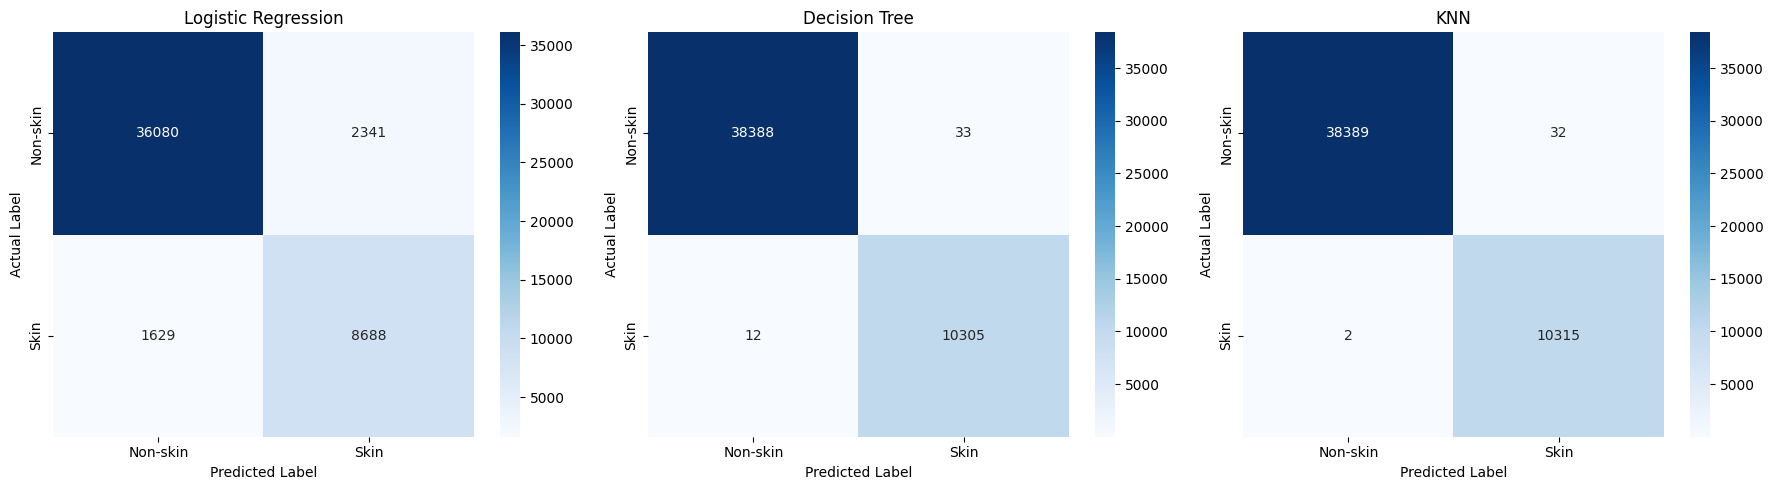

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, name in zip(axes, models.keys()):

    cm = confusion_matrix(
        y_test,
        predictions[name],
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Non-skin", "Skin"],
        yticklabels=["Non-skin", "Skin"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

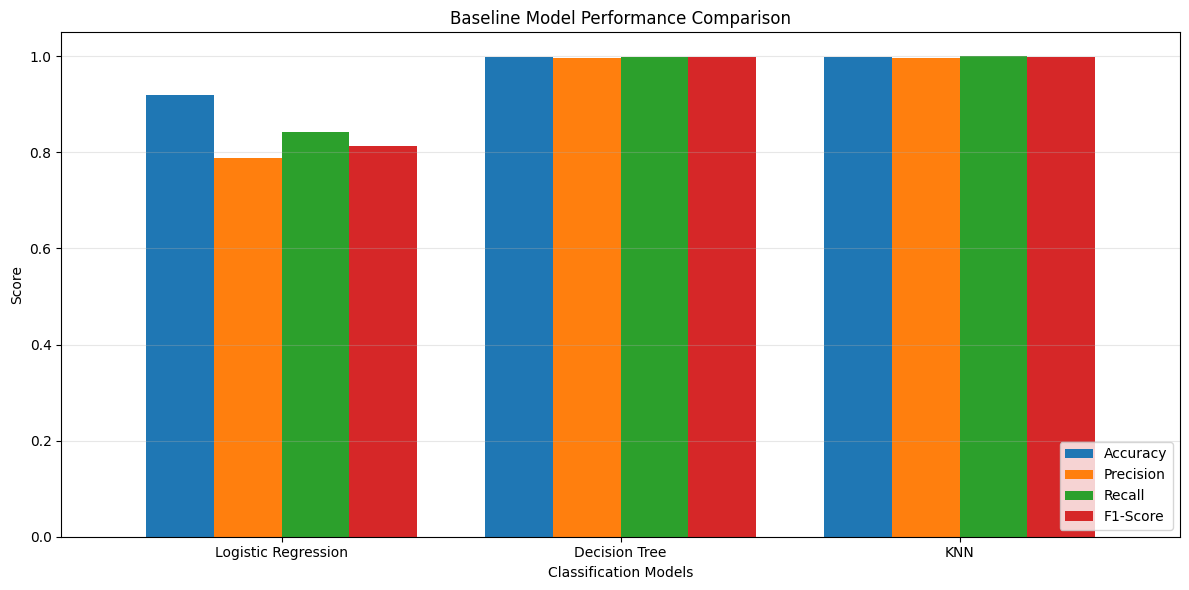

In [ ]:
# Model performance comparison

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

comparison = baseline_results.set_index("Model")[metrics]

ax = comparison.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Baseline Model Performance Comparison")
plt.xlabel("Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("baseline_model_comparison.png", dpi=300)
plt.show()

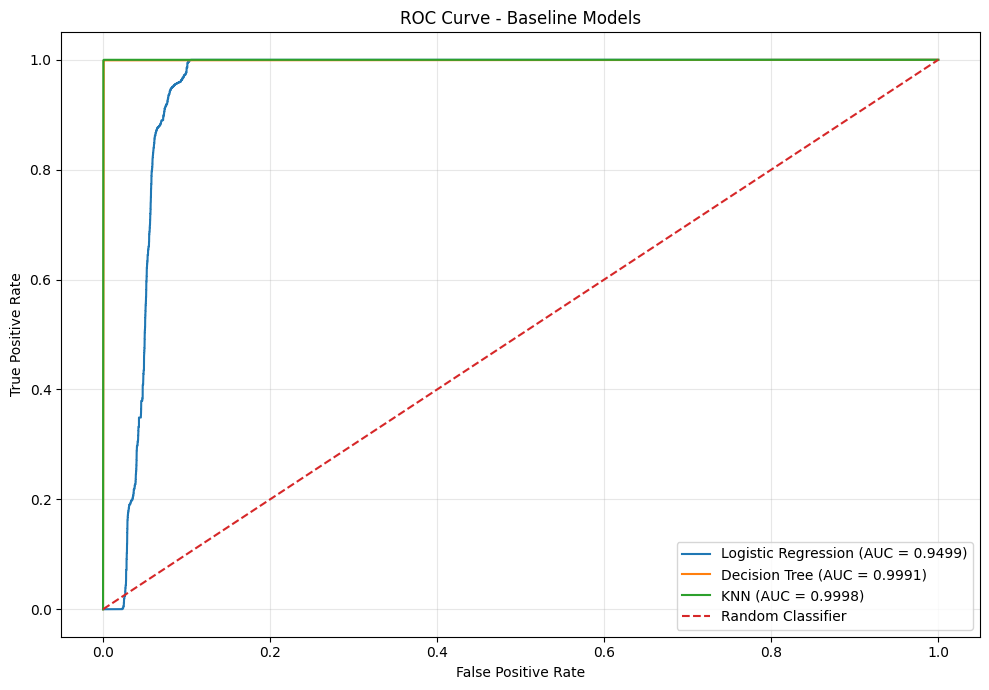

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score, auc

plt.figure(figsize=(10, 7))

auc_results = []

for name in models.keys():

    y_prob = probabilities[name]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob,
        pos_label=1
    )

    roc_auc = roc_auc_score(y_test, y_prob)

    auc_results.append({
        "Model": name,
        "ROC-AUC": roc_auc
    })

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.4f})"
    )

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve - Baseline Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("baseline_roc_curves.png", dpi=300)
plt.show()

In [ ]:
auc_df = pd.DataFrame(auc_results)

display(
    auc_df.style.format({
        "ROC-AUC": "{:.4f}"
    })
)

,Model,ROC-AUC
0,Logistic Regression,0.9499
1,Decision Tree,0.9991
2,KNN,0.9998


In [ ]:
# Save model comparison
baseline_results.to_csv(
    "baseline_model_results.csv",
    index=False
)

# Save AUC results
auc_df.to_csv(
    "baseline_auc_results.csv",
    index=False
)

print("Baseline results saved successfully!")

Baseline results saved successfully!


In [ ]:
import joblib

for name, model in trained_models.items():

    filename = name.lower().replace(" ", "_") + ".pkl"

    joblib.dump(model, filename)

# Save scaler
joblib.dump(scaler, "standard_scaler.pkl")

print("Models and scaler saved successfully!")

Models and scaler saved successfully!


New section : Advanced modeling

In [ ]:
!pip install xgboost -q

In [ ]:
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)

from xgboost import XGBClassifier

from sklearn.svm import LinearSVC

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [ ]:
advanced_models = {

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ),

    "SVM": LinearSVC(
        C=1.0,
        max_iter=5000,
        random_state=42
    ),

    "MLP": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=100,
        early_stopping=True,
        random_state=42
    )
}

In [ ]:
advanced_results = []

advanced_trained_models = {}
advanced_predictions = {}
advanced_scores = {}

for name, model in advanced_models.items():

    print("\n" + "=" * 55)
    print(f"Training {name}")
    print("=" * 55)

    # Select appropriate features
    if name in ["SVM", "MLP"]:
        Xtr = X_train_scaled
        Xte = X_test_scaled
    else:
        Xtr = X_train
        Xte = X_test

    # Train
    start_time = time.perf_counter()

    model.fit(Xtr, y_train)

    training_time = time.perf_counter() - start_time

    # Predict
    start_time = time.perf_counter()

    y_pred = model.predict(Xte)

    prediction_time = time.perf_counter() - start_time

    # Obtain scores for ROC-AUC
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(Xte)[:, 1]
    else:
        y_score = model.decision_function(Xte)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, pos_label=1
    )

    recall = recall_score(
        y_test, y_pred, pos_label=1
    )

    f1 = f1_score(
        y_test, y_pred, pos_label=1
    )

    auc_score = roc_auc_score(
        y_test, y_score
    )

    # Store results
    advanced_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": auc_score,
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time
    })

    advanced_trained_models[name] = model
    advanced_predictions[name] = y_pred
    advanced_scores[name] = y_score

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"ROC-AUC: {auc_score:.4f}")
    print(f"Training time: {training_time:.2f} seconds")
    print(f"Prediction time: {prediction_time:.2f} seconds")


Training Random Forest
Accuracy: 0.9992
Precision: 0.9970
Recall: 0.9994
F1-score: 0.9982
ROC-AUC: 1.0000
Training time: 10.90 seconds
Prediction time: 0.17 seconds

Training Gradient Boosting
Accuracy: 0.9992
Precision: 0.9966
Recall: 0.9997
F1-score: 0.9982
ROC-AUC: 1.0000
Training time: 2.07 seconds
Prediction time: 0.70 seconds

Training XGBoost
Accuracy: 0.9992
Precision: 0.9969
Recall: 0.9994
F1-score: 0.9982
ROC-AUC: 1.0000
Training time: 7.37 seconds
Prediction time: 0.23 seconds

Training SVM
Accuracy: 0.9246
Precision: 0.7912
Recall: 0.8748
F1-score: 0.8309
ROC-AUC: 0.9464
Training time: 0.13 seconds
Prediction time: 0.00 seconds

Training MLP
Accuracy: 0.9991
Precision: 0.9963
Recall: 0.9993
F1-score: 0.9978
ROC-AUC: 1.0000
Training time: 15.56 seconds
Prediction time: 0.02 seconds


In [ ]:
advanced_results = []

advanced_trained_models = {}
advanced_predictions = {}
advanced_scores = {}

for name, model in advanced_models.items():

    print("\n" + "=" * 55)
    print(f"Training {name}")
    print("=" * 55)

    # Select appropriate features
    if name in ["SVM", "MLP"]:
        Xtr = X_train_scaled
        Xte = X_test_scaled
    else:
        Xtr = X_train
        Xte = X_test

    # Train
    start_time = time.perf_counter()

    model.fit(Xtr, y_train)

    training_time = time.perf_counter() - start_time

    # Predict
    start_time = time.perf_counter()

    y_pred = model.predict(Xte)

    prediction_time = time.perf_counter() - start_time

    # Obtain scores for ROC-AUC
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(Xte)[:, 1]
    else:
        y_score = model.decision_function(Xte)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, pos_label=1
    )

    recall = recall_score(
        y_test, y_pred, pos_label=1
    )

    f1 = f1_score(
        y_test, y_pred, pos_label=1
    )

    auc_score = roc_auc_score(
        y_test, y_score
    )

    # Store results
    advanced_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": auc_score,
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time
    })

    advanced_trained_models[name] = model
    advanced_predictions[name] = y_pred
    advanced_scores[name] = y_score

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"ROC-AUC: {auc_score:.4f}")
    print(f"Training time: {training_time:.2f} seconds")
    print(f"Prediction time: {prediction_time:.2f} seconds")


Training Random Forest
Accuracy: 0.9992
Precision: 0.9970
Recall: 0.9994
F1-score: 0.9982
ROC-AUC: 1.0000
Training time: 10.96 seconds
Prediction time: 0.16 seconds

Training Gradient Boosting
Accuracy: 0.9992
Precision: 0.9966
Recall: 0.9997
F1-score: 0.9982
ROC-AUC: 1.0000
Training time: 1.77 seconds
Prediction time: 0.47 seconds

Training XGBoost
Accuracy: 0.9992
Precision: 0.9969
Recall: 0.9994
F1-score: 0.9982
ROC-AUC: 1.0000
Training time: 1.39 seconds
Prediction time: 0.10 seconds

Training SVM
Accuracy: 0.9246
Precision: 0.7912
Recall: 0.8748
F1-score: 0.8309
ROC-AUC: 0.9464
Training time: 0.07 seconds
Prediction time: 0.00 seconds

Training MLP
Accuracy: 0.9991
Precision: 0.9963
Recall: 0.9993
F1-score: 0.9978
ROC-AUC: 1.0000
Training time: 18.87 seconds
Prediction time: 0.05 seconds


In [ ]:
advanced_results_df = pd.DataFrame(advanced_results)

display(
    advanced_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Training Time (s)": "{:.2f}",
        "Prediction Time (s)": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Training Time (s),Prediction Time (s)
0,Random Forest,0.9992,0.9970,0.9994,0.9982,1.0000,10.96,0.1637
1,Gradient Boosting,0.9992,0.9966,0.9997,0.9982,1.0000,1.77,0.4669
2,XGBoost,0.9992,0.9969,0.9994,0.9982,1.0000,1.39,0.1037
3,SVM,0.9246,0.7912,0.8748,0.8309,0.9464,0.07,0.0007
4,MLP,0.9991,0.9963,0.9993,0.9978,1.0000,18.87,0.0498


In [ ]:
all_results = pd.concat(
    [
        baseline_results,
        advanced_results_df
    ],
    ignore_index=True
)

display(
    all_results.sort_values(
        by="F1-Score",
        ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy,Precision,Recall,F1-Score,Training Time (s),Prediction Time (s),ROC-AUC
0,KNN,0.999302,0.996907,0.999806,0.998355,0.317724,0.642725,NaN
1,Random Forest,0.999241,0.997003,0.999418,0.998209,10.964965,0.163716,0.999981
2,Gradient Boosting,0.999220,0.996618,0.999709,0.998161,1.771532,0.466867,0.999980
3,XGBoost,0.999220,0.996906,0.999418,0.998161,1.390531,0.103719,0.999973
4,MLP,0.999077,0.996328,0.999322,0.997822,18.868575,0.049848,0.999965
5,Decision Tree,0.999077,0.996808,0.998837,0.997821,0.479254,0.003289,NaN
6,SVM,0.924617,0.791181,0.874770,0.830878,0.071684,0.000730,0.946430
7,Logistic Regression,0.918544,0.787741,0.842105,0.814017,0.299558,0.000762,NaN


In [ ]:
advanced_results_df.to_csv(
    "advanced_model_results.csv",
    index=False
)

all_results.to_csv(
    "all_model_comparison.csv",
    index=False
)

print("Advanced modeling results saved!")

Advanced modeling results saved!


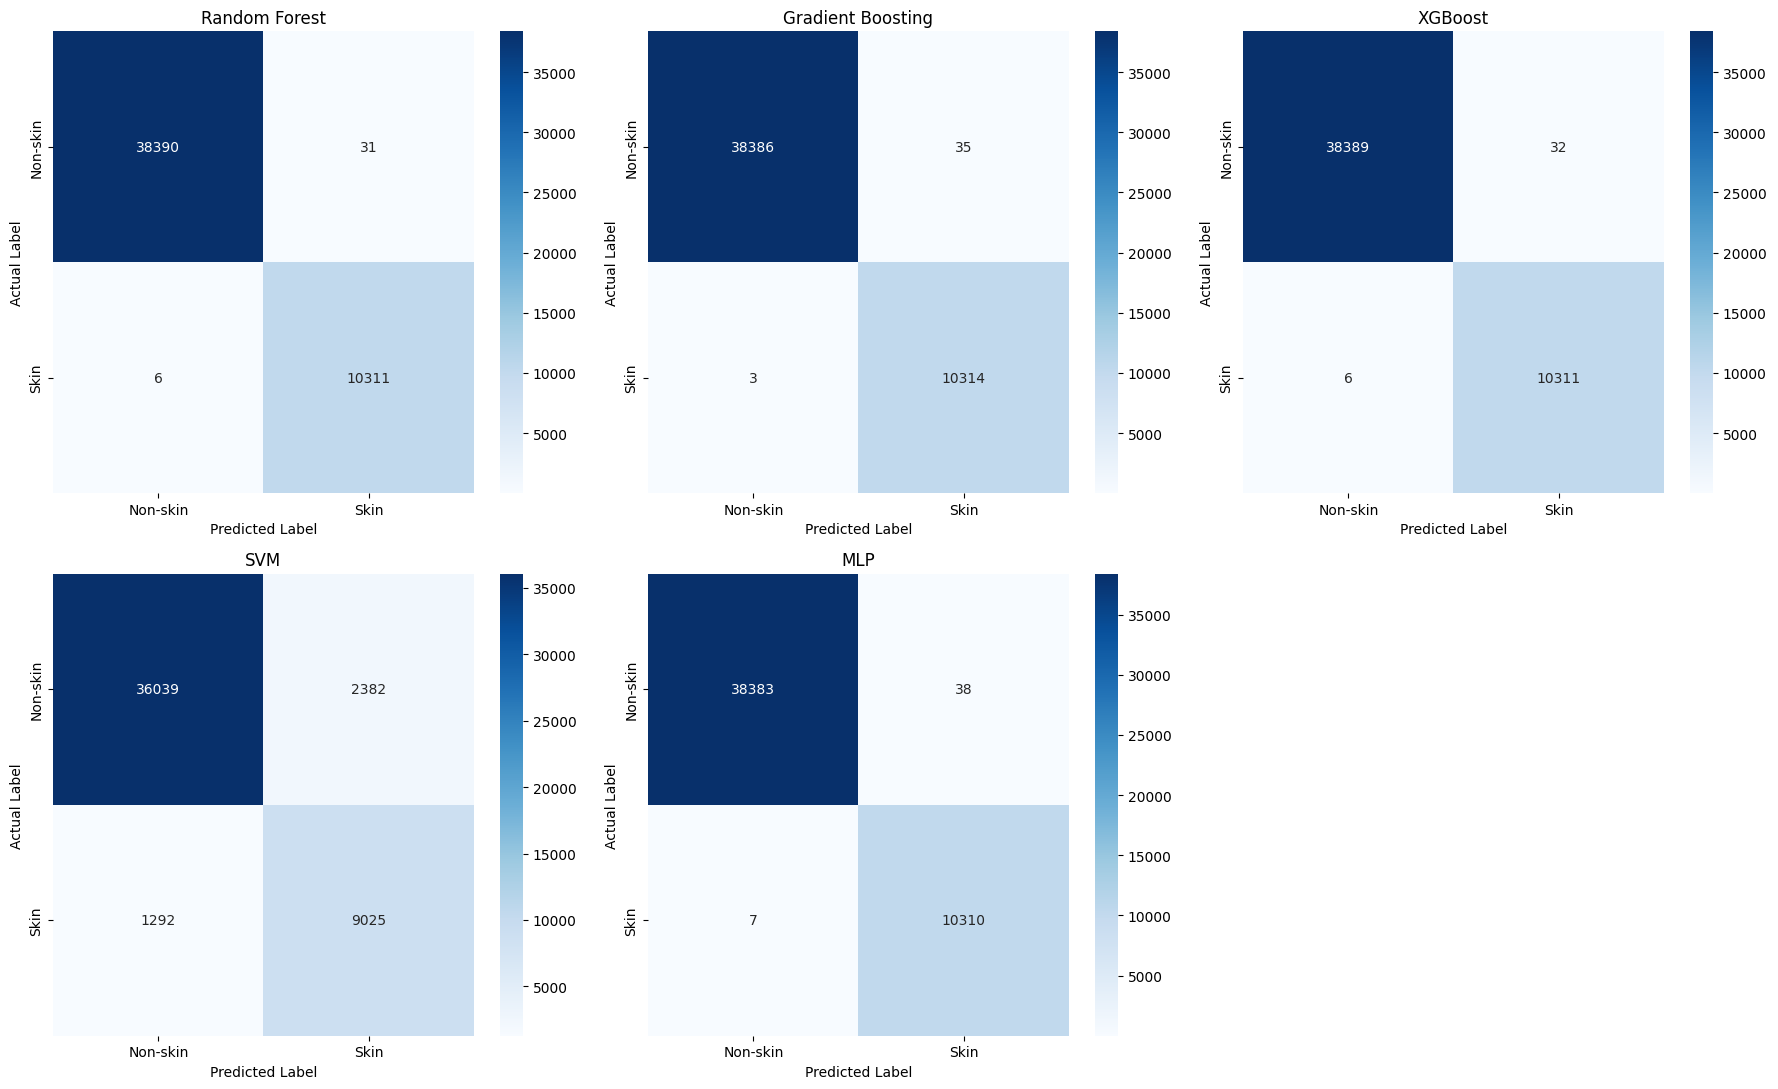

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

for ax, name in zip(axes.flatten(), advanced_models.keys()):

    cm = confusion_matrix(
        y_test,
        advanced_predictions[name],
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Non-skin", "Skin"],
        yticklabels=["Non-skin", "Skin"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

# Hide unused subplot
axes.flatten()[-1].axis("off")

plt.tight_layout()
plt.show()

cross-validation and hyper parameter tuning

In [ ]:
from sklearn.model_selection import (
    StratifiedGroupKFold,
    RandomizedSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Groups corresponding to training observations
groups_train = groups.iloc[train_idx]

# Five-fold group-aware cross-validation
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation strategy: 5-fold StratifiedGroupKFold")
print("Training observations:", len(X_train))
print("Unique training groups:", groups_train.nunique())

Cross-validation strategy: 5-fold StratifiedGroupKFold
Training observations: 196319
Unique training groups: 41148


In [ ]:
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)

from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

# Models and their parameter search spaces

tuning_config = {

    "Random Forest": {
        "pipeline": Pipeline([
            ("model", RandomForestClassifier(
                random_state=42,
                n_jobs=1
            ))
        ]),
        "params": {
            "model__n_estimators": [100, 200, 300],
            "model__max_depth": [None, 10, 20, 30],
            "model__min_samples_split": [2, 5, 10],
            "model__min_samples_leaf": [1, 2, 4],
            "model__max_features": ["sqrt", 1.0]
        }
    },

    "Gradient Boosting": {
        "pipeline": Pipeline([
            ("model", HistGradientBoostingClassifier(
                random_state=42
            ))
        ]),
        "params": {
            "model__max_iter": [100, 150, 200],
            "model__learning_rate": [0.03, 0.05, 0.1],
            "model__max_leaf_nodes": [15, 31, 63],
            "model__l2_regularization": [0, 0.1, 1.0]
        }
    },

    "XGBoost": {
        "pipeline": Pipeline([
            ("model", XGBClassifier(
                objective="binary:logistic",
                eval_metric="logloss",
                tree_method="hist",
                random_state=42,
                n_jobs=1
            ))
        ]),
        "params": {
            "model__n_estimators": [100, 200, 300],
            "model__max_depth": [3, 5, 7],
            "model__learning_rate": [0.03, 0.05, 0.1],
            "model__subsample": [0.7, 0.8, 1.0],
            "model__colsample_bytree": [0.7, 0.8, 1.0]
        }
    },

    "SVM": {
        "pipeline": Pipeline([
            ("scaler", StandardScaler()),
            ("model", LinearSVC(
                random_state=42,
                max_iter=10000
            ))
        ]),
        "params": {
            "model__C": [0.01, 0.1, 1, 10],
            "model__loss": ["hinge", "squared_hinge"],
            "model__class_weight": [None, "balanced"]
        }
    },

    "MLP": {
        "pipeline": Pipeline([
            ("scaler", StandardScaler()),
            ("model", MLPClassifier(
                max_iter=150,
                early_stopping=True,
                random_state=42
            ))
        ]),
        "params": {
            "model__hidden_layer_sizes": [
                (32, 16),
                (64, 32),
                (100, 50)
            ],
            "model__activation": ["relu", "tanh"],
            "model__alpha": [0.0001, 0.001, 0.01],
            "model__learning_rate_init": [0.001, 0.01]
        }
    }
}

In [ ]:
tuned_models = {}
tuning_results = []

for name, config in tuning_config.items():

    print("\n" + "=" * 60)
    print("TUNING:", name)
    print("=" * 60)

    search = RandomizedSearchCV(
        estimator=config["pipeline"],
        param_distributions=config["params"],
        n_iter=5,
        scoring="f1",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        verbose=1,
        refit=True,
        return_train_score=True
    )

    start_time = time.perf_counter()

    search.fit(
        X_train,
        y_train,
        groups=groups_train
    )

    elapsed = time.perf_counter() - start_time

    tuned_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV F1": search.best_score_,
        "Best Parameters": search.best_params_,
        "Tuning Time (s)": elapsed
    })

    print("\nBest CV F1:", round(search.best_score_, 5))
    print("Best parameters:", search.best_params_)
    print("Tuning time:", round(elapsed, 2), "seconds")


TUNING: Random Forest
Fitting 5 folds for each of 5 candidates, totalling 25 fits

Best CV F1: 0.99875
Best parameters: {'model__n_estimators': 100, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': 30}
Tuning time: 228.57 seconds

TUNING: Gradient Boosting
Fitting 5 folds for each of 5 candidates, totalling 25 fits

Best CV F1: 0.99862
Best parameters: {'model__max_leaf_nodes': 31, 'model__max_iter': 150, 'model__learning_rate': 0.1, 'model__l2_regularization': 0}
Tuning time: 64.03 seconds

TUNING: XGBoost
Fitting 5 folds for each of 5 candidates, totalling 25 fits

Best CV F1: 0.99875
Best parameters: {'model__subsample': 0.8, 'model__n_estimators': 200, 'model__max_depth': 7, 'model__learning_rate': 0.1, 'model__colsample_bytree': 1.0}
Tuning time: 64.17 seconds

TUNING: SVM
Fitting 5 folds for each of 5 candidates, totalling 25 fits


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(



Best CV F1: 0.85618
Best parameters: {'model__loss': 'hinge', 'model__class_weight': 'balanced', 'model__C': 10}
Tuning time: 45.12 seconds

TUNING: MLP
Fitting 5 folds for each of 5 candidates, totalling 25 fits

Best CV F1: 0.99857
Best parameters: {'model__learning_rate_init': 0.001, 'model__hidden_layer_sizes': (64, 32), 'model__alpha': 0.001, 'model__activation': 'tanh'}
Tuning time: 302.64 seconds


In [ ]:
tuning_df = pd.DataFrame(tuning_results)

display(
    tuning_df[
        ["Model", "Best CV F1", "Tuning Time (s)"]
    ].style.format({
        "Best CV F1": "{:.5f}",
        "Tuning Time (s)": "{:.2f}"
    })
)

,Model,Best CV F1,Tuning Time (s)
0,Random Forest,0.99875,228.57
1,Gradient Boosting,0.99862,64.03
2,XGBoost,0.99875,64.17
3,SVM,0.85618,45.12
4,MLP,0.99857,302.64


In [ ]:
for result in tuning_results:

    print("\n", result["Model"])
    print("Best parameters:")
    print(result["Best Parameters"])


 Random Forest
Best parameters:
{'model__n_estimators': 100, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': 30}

 Gradient Boosting
Best parameters:
{'model__max_leaf_nodes': 31, 'model__max_iter': 150, 'model__learning_rate': 0.1, 'model__l2_regularization': 0}

 XGBoost
Best parameters:
{'model__subsample': 0.8, 'model__n_estimators': 200, 'model__max_depth': 7, 'model__learning_rate': 0.1, 'model__colsample_bytree': 1.0}

 SVM
Best parameters:
{'model__loss': 'hinge', 'model__class_weight': 'balanced', 'model__C': 10}

 MLP
Best parameters:
{'model__learning_rate_init': 0.001, 'model__hidden_layer_sizes': (64, 32), 'model__alpha': 0.001, 'model__activation': 'tanh'}


In [ ]:
tuned_test_results = []
tuned_predictions = {}
tuned_scores = {}

for name, model in tuned_models.items():

    print("\nEvaluating:", name)

    y_pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc_score = roc_auc_score(y_test, y_score)

    tuned_test_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": auc_score
    })

    tuned_predictions[name] = y_pred
    tuned_scores[name] = y_score

tuned_test_df = pd.DataFrame(tuned_test_results)

display(tuned_test_df.round(5))


Evaluating: Random Forest

Evaluating: Gradient Boosting

Evaluating: XGBoost

Evaluating: SVM

Evaluating: MLP


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.99924,0.99710,0.99932,0.99821,0.99999
1,Gradient Boosting,0.99922,0.99662,0.99971,0.99816,0.99998
2,XGBoost,0.99918,0.99671,0.99942,0.99806,0.99998
3,SVM,0.92798,0.74615,1.00000,0.85462,0.93574
4,MLP,0.99904,0.99575,0.99971,0.99773,0.99992


In [ ]:
default_comparison = advanced_results_df[
    ["Model", "F1-Score", "ROC-AUC"]
].rename(columns={
    "F1-Score": "Default F1",
    "ROC-AUC": "Default AUC"
})

tuned_comparison = tuned_test_df[
    ["Model", "F1-Score", "ROC-AUC"]
].rename(columns={
    "F1-Score": "Tuned F1",
    "ROC-AUC": "Tuned AUC"
})

tuning_comparison = default_comparison.merge(
    tuned_comparison,
    on="Model"
)

tuning_comparison["F1 Improvement"] = (
    tuning_comparison["Tuned F1"] -
    tuning_comparison["Default F1"]
)

display(tuning_comparison.round(6))

,Model,Default F1,Default AUC,Tuned F1,Tuned AUC,F1 Improvement
0,Random Forest,0.998209,0.999981,0.998209,0.999990,-0.000000
1,Gradient Boosting,0.998161,0.999980,0.998161,0.999980,0.000000
2,XGBoost,0.998161,0.999973,0.998064,0.999981,-0.000097
3,SVM,0.830878,0.946430,0.854622,0.935744,0.023744
4,MLP,0.997822,0.999965,0.997727,0.999922,-0.000096


In [ ]:
for name, model in tuned_models.items():

    filename = (
        "tuned_" +
        name.lower().replace(" ", "_") +
        ".pkl"
    )

    joblib.dump(model, filename)

tuning_df.to_csv("hyperparameter_search_results.csv", index=False)

tuned_test_df.to_csv("tuned_test_results.csv", index=False)

tuning_comparison.to_csv("default_vs_tuned.csv", index=False)

print("All tuned models and results saved!")

All tuned models and results saved!


class imbalance

In [ ]:
!pip install imbalanced-learn -q

In [ ]:
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.base import clone
from sklearn.model_selection import cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [ ]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

imbalance_ratio = negative_count / positive_count

print("Non-skin samples:", negative_count)
print("Skin samples:", positive_count)
print("Imbalance ratio:", round(imbalance_ratio, 4))

Non-skin samples: 155777
Skin samples: 40542
Imbalance ratio: 3.8424


In [ ]:
def create_model(model_name, strategy):

    if model_name == "Logistic Regression":

        steps = [
            ("scaler", StandardScaler())
        ]

        if strategy == "oversampling":
            steps.append((
                "sampler",
                RandomOverSampler(random_state=42)
            ))

        elif strategy == "undersampling":
            steps.append((
                "sampler",
                RandomUnderSampler(random_state=42)
            ))

        steps.append((
            "classifier",
            LogisticRegression(
                max_iter=2000,
                class_weight=(
                    "balanced" if strategy == "class_weight" else None
                ),
                random_state=42
            )
        ))

        return ImbPipeline(steps)

    elif model_name == "Random Forest":

        steps = []

        if strategy == "oversampling":
            steps.append((
                "sampler",
                RandomOverSampler(random_state=42)
            ))

        elif strategy == "undersampling":
            steps.append((
                "sampler",
                RandomUnderSampler(random_state=42)
            ))

        steps.append((
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=None,
                class_weight=(
                    "balanced" if strategy == "class_weight" else None
                ),
                random_state=42,
                n_jobs=1
            )
        ))

        return ImbPipeline(steps)

    elif model_name == "XGBoost":

        steps = []

        if strategy == "oversampling":
            steps.append((
                "sampler",
                RandomOverSampler(random_state=42)
            ))

        elif strategy == "undersampling":
            steps.append((
                "sampler",
                RandomUnderSampler(random_state=42)
            ))

        steps.append((
            "classifier",
            XGBClassifier(
                n_estimators=200,
                max_depth=6,
                learning_rate=0.1,
                objective="binary:logistic",
                eval_metric="logloss",
                tree_method="hist",
                scale_pos_weight=(
                    imbalance_ratio if strategy == "class_weight" else 1
                ),
                random_state=42,
                n_jobs=1
            )
        ))

        return ImbPipeline(steps)

In [ ]:
model_names = [
    "Logistic Regression",
    "Random Forest",
    "XGBoost"
]

strategies = [
    "original",
    "class_weight",
    "oversampling",
    "undersampling"
]

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

imbalance_results = []
imbalance_models = {}
imbalance_predictions = {}

groups_train_array = groups.iloc[train_idx].to_numpy()

for model_name in model_names:

    for strategy in strategies:

        print("\n" + "=" * 60)
        print(model_name, "-", strategy)
        print("=" * 60)

        model = create_model(model_name, strategy)

        # Group-aware cross-validation
        cv_results = cross_validate(
            model,
            X_train,
            y_train,
            groups=groups_train_array,
            cv=cv,
            scoring=scoring,
            n_jobs=-1,
            return_train_score=False
        )

        # Fit on the complete training set
        model.fit(X_train, y_train)

        # Evaluate on untouched test set
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        row = {
            "Model": model_name,
            "Strategy": strategy,

            "CV F1 Mean": cv_results["test_f1"].mean(),
            "CV F1 Std": cv_results["test_f1"].std(),

            "Test Accuracy": accuracy_score(y_test, y_pred),
            "Test Precision": precision_score(y_test, y_pred),
            "Test Recall": recall_score(y_test, y_pred),
            "Test F1": f1_score(y_test, y_pred),
            "Test ROC-AUC": roc_auc_score(y_test, y_prob)
        }

        imbalance_results.append(row)

        key = f"{model_name}_{strategy}"

        imbalance_models[key] = model
        imbalance_predictions[key] = y_pred

        print("CV F1:", round(row["CV F1 Mean"], 5))
        print("Test F1:", round(row["Test F1"], 5))
        print("Test Recall:", round(row["Test Recall"], 5))


Logistic Regression - original
CV F1: 0.8124
Test F1: 0.81402
Test Recall: 0.84211

Logistic Regression - class_weight
CV F1: 0.84469
Test F1: 0.85099
Test Recall: 0.96734

Logistic Regression - oversampling
CV F1: 0.84431
Test F1: 0.85099
Test Recall: 0.96734

Logistic Regression - undersampling
CV F1: 0.84543
Test F1: 0.84977
Test Recall: 0.96578

Random Forest - original
CV F1: 0.99886
Test F1: 0.99821
Test Recall: 0.99942

Random Forest - class_weight
CV F1: 0.99878
Test F1: 0.99835
Test Recall: 0.99952

Random Forest - oversampling
CV F1: 0.99875
Test F1: 0.9984
Test Recall: 0.99971

Random Forest - undersampling
CV F1: 0.99715
Test F1: 0.997
Test Recall: 0.99961

XGBoost - original
CV F1: 0.99853
Test F1: 0.99811
Test Recall: 0.99942

XGBoost - class_weight
CV F1: 0.99851
Test F1: 0.99787
Test Recall: 0.99952

XGBoost - oversampling
CV F1: 0.99848
Test F1: 0.99797
Test Recall: 0.99952

XGBoost - undersampling
CV F1: 0.99735
Test F1: 0.99676
Test Recall: 0.99961


In [ ]:
imbalance_df = pd.DataFrame(imbalance_results)

display(
    imbalance_df.sort_values(
        by="Test F1",
        ascending=False
    ).round(5)
)

,Model,Strategy,CV F1 Mean,CV F1 Std,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
6,Random Forest,oversampling,0.99875,0.00021,0.99932,0.99710,0.99971,0.99840,0.99997
5,Random Forest,class_weight,0.99878,0.00028,0.99930,0.99720,0.99952,0.99835,0.99998
4,Random Forest,original,0.99886,0.00020,0.99924,0.99700,0.99942,0.99821,0.99998
8,XGBoost,original,0.99853,0.00020,0.99920,0.99681,0.99942,0.99811,0.99997
10,XGBoost,oversampling,0.99848,0.00029,0.99914,0.99642,0.99952,0.99797,0.99997
9,XGBoost,class_weight,0.99851,0.00019,0.99910,0.99623,0.99952,0.99787,0.99997
7,Random Forest,undersampling,0.99715,0.00094,0.99873,0.99441,0.99961,0.99700,0.99997
11,XGBoost,undersampling,0.99735,0.00046,0.99863,0.99393,0.99961,0.99676,0.99996
2,Logistic Regression,oversampling,0.84431,0.01997,0.92829,0.75963,0.96734,0.85099,0.94300
1,Logistic Regression,class_weight,0.84469,0.02009,0.92829,0.75963,0.96734,0.85099,0.94299


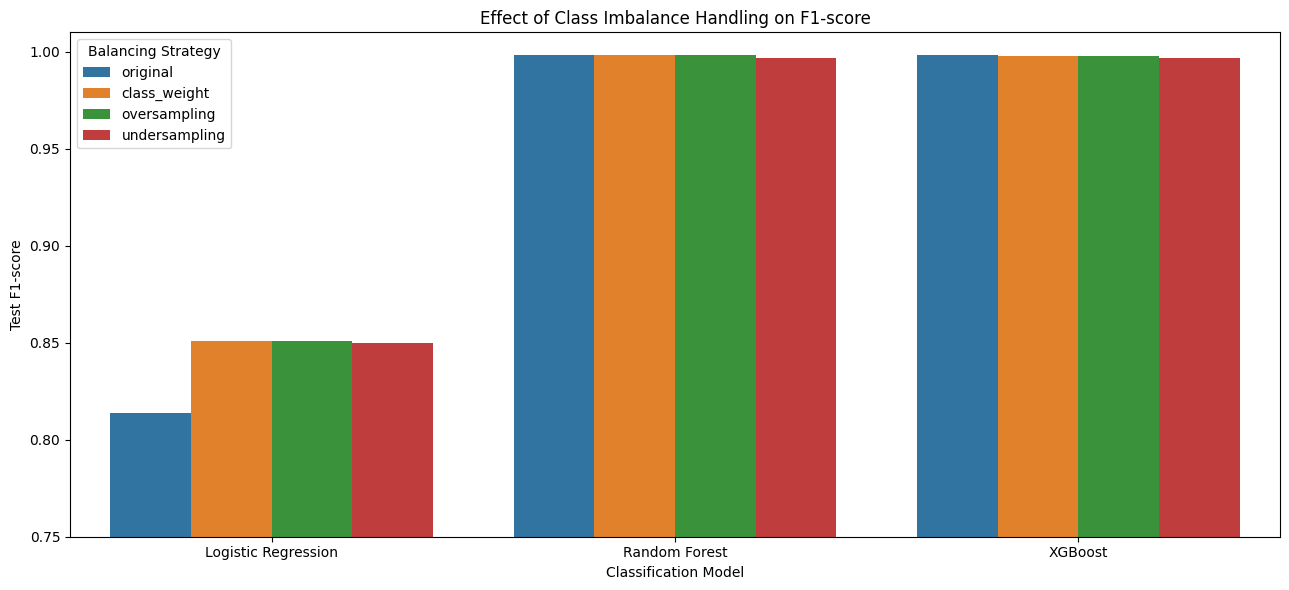

In [ ]:
plt.figure(figsize=(13, 6))

sns.barplot(
    data=imbalance_df,
    x="Model",
    y="Test F1",
    hue="Strategy"
)

plt.title("Effect of Class Imbalance Handling on F1-score")
plt.ylim(0.75, 1.01)
plt.ylabel("Test F1-score")
plt.xlabel("Classification Model")
plt.legend(title="Balancing Strategy")
plt.tight_layout()
plt.show()

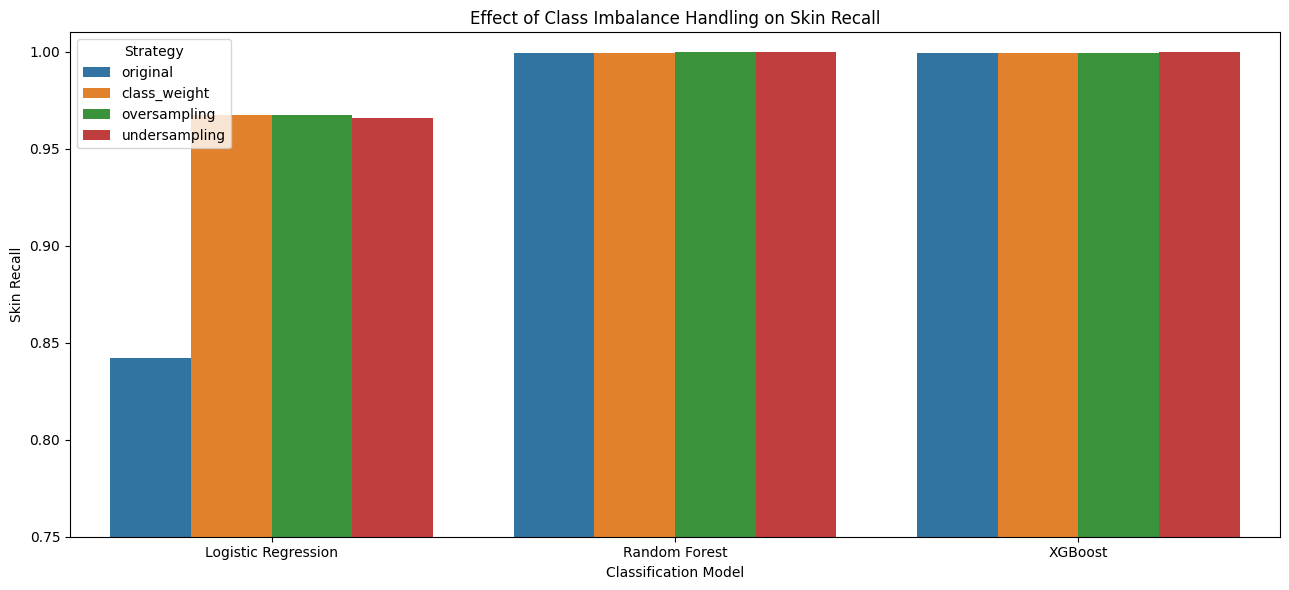

In [ ]:
plt.figure(figsize=(13, 6))

sns.barplot(
    data=imbalance_df,
    x="Model",
    y="Test Recall",
    hue="Strategy"
)

plt.title("Effect of Class Imbalance Handling on Skin Recall")
plt.ylim(0.75, 1.01)
plt.ylabel("Skin Recall")
plt.xlabel("Classification Model")
plt.tight_layout()
plt.show()

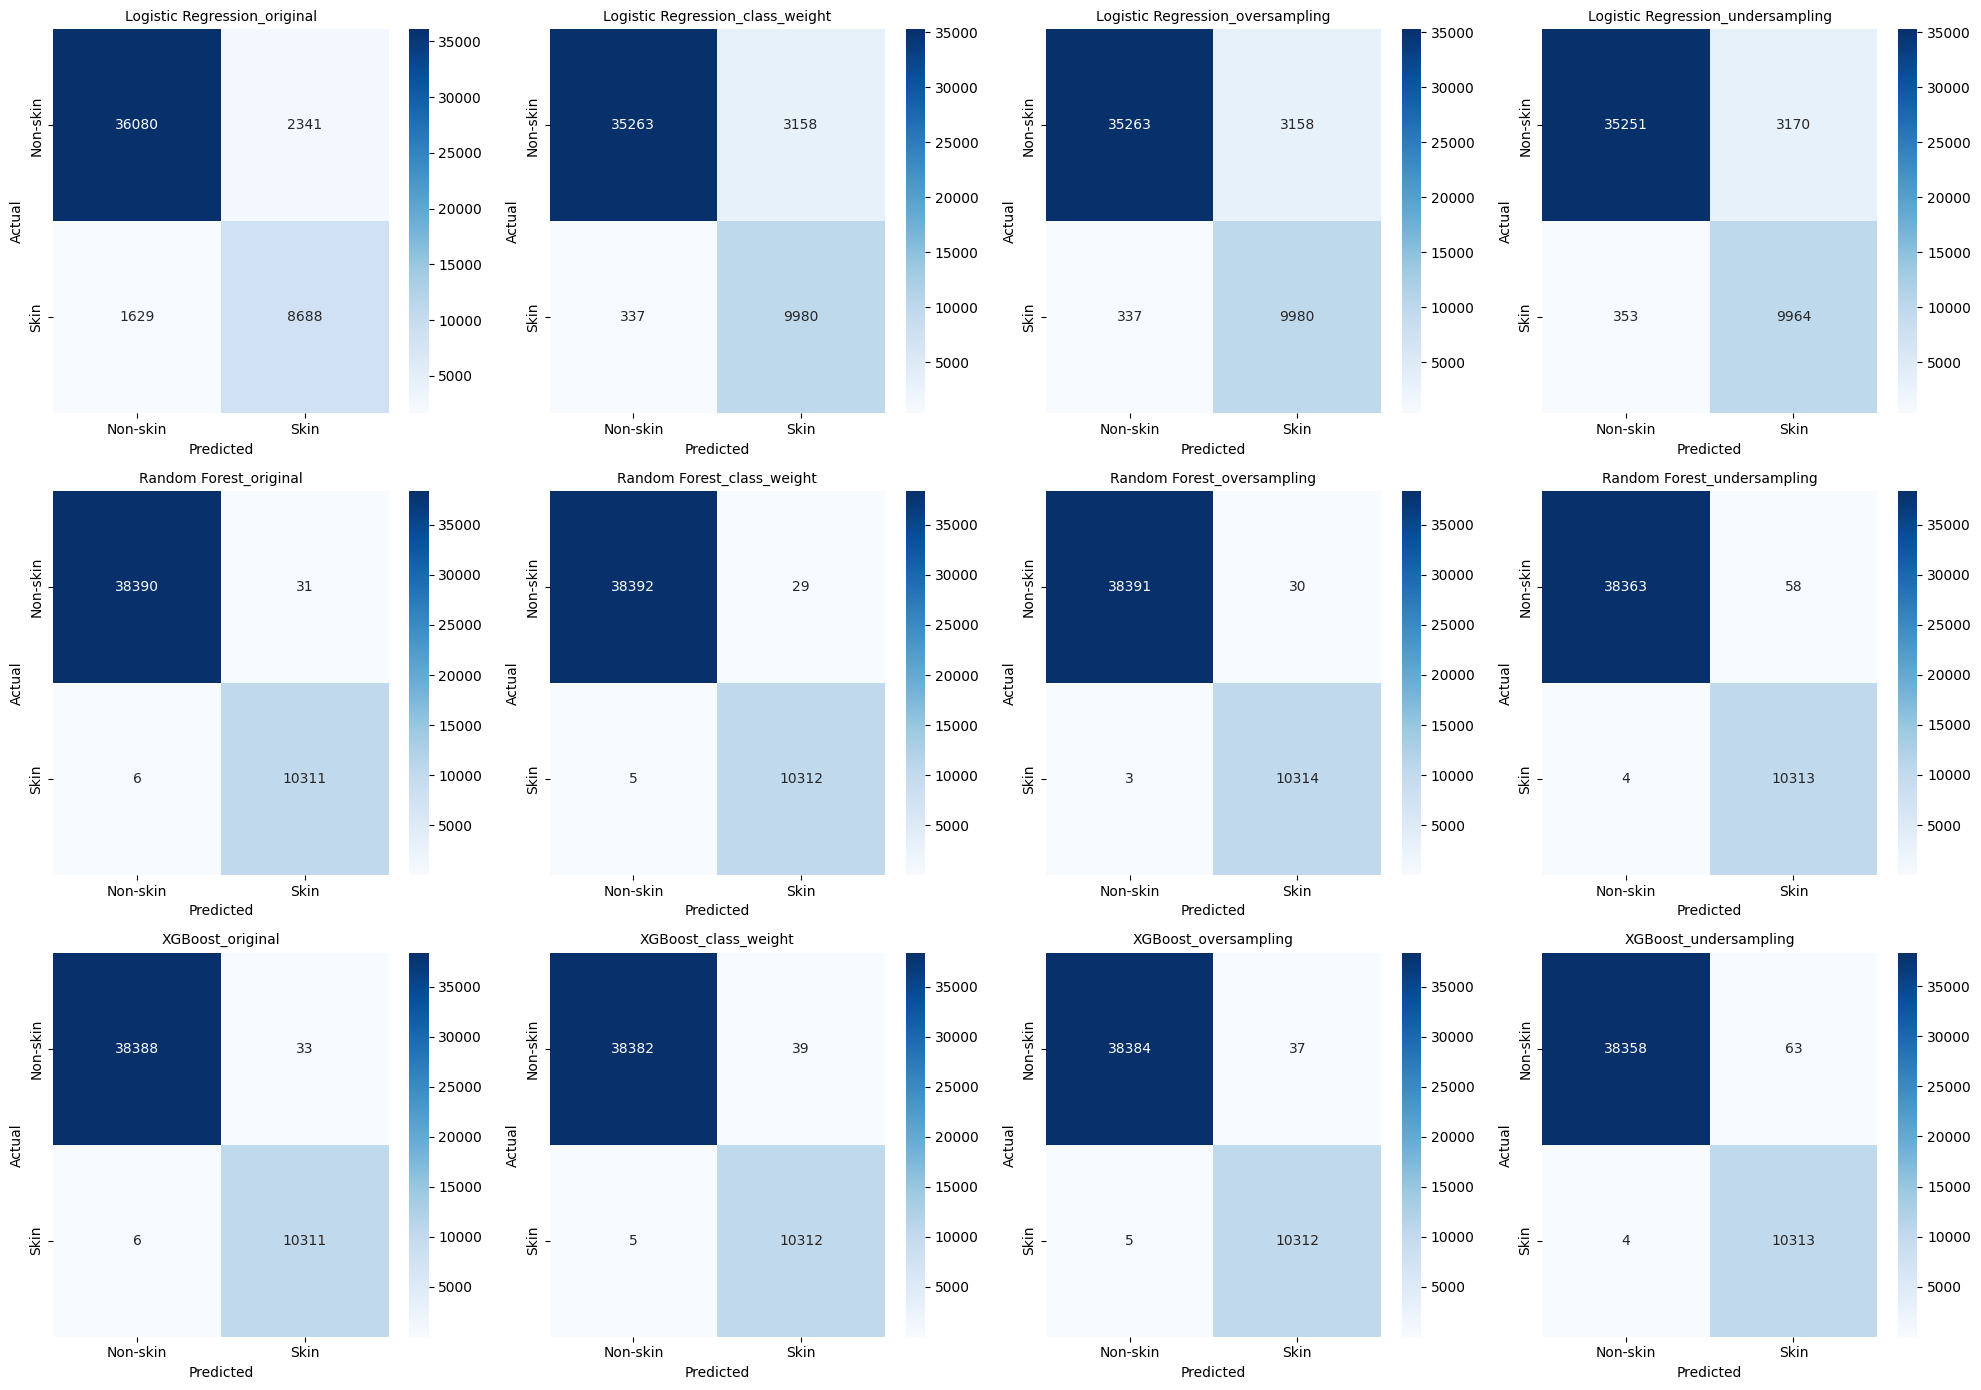

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(20, 14))

for ax, (key, y_pred) in zip(
    axes.flatten(),
    imbalance_predictions.items()
):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Non-skin", "Skin"],
        yticklabels=["Non-skin", "Skin"],
        ax=ax
    )

    ax.set_title(key, fontsize=10)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [ ]:
imbalance_df.to_csv(
    "class_imbalance_experiments.csv",
    index=False
)

for name, model in imbalance_models.items():

    filename = (
        "imbalance_" +
        name.lower().replace(" ", "_") +
        ".pkl"
    )

    joblib.dump(model, filename)

print("Class imbalance experiments saved!")

Class imbalance experiments saved!


phase 5

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Retrieve trained Random Forest
rf_model = advanced_trained_models["Random Forest"]

# Extract feature importance
rf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

display(rf_importance)

,Feature,Importance
2,R,0.546983
1,G,0.234253
0,B,0.218765


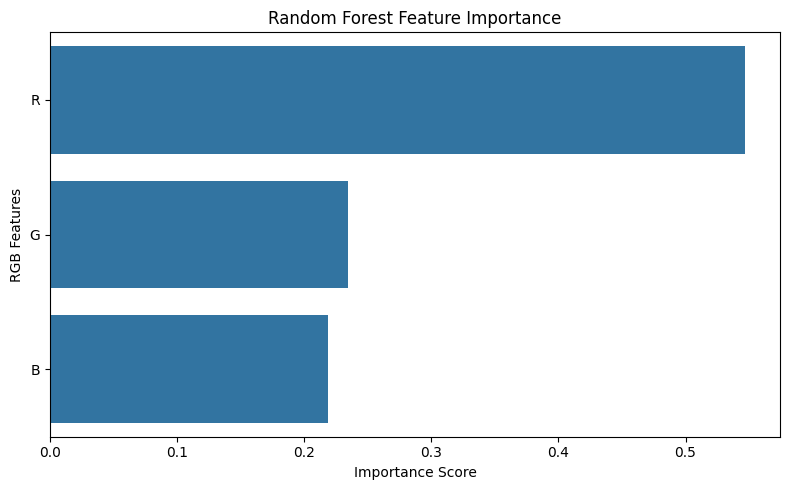

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=rf_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("RGB Features")

plt.tight_layout()
plt.show()

In [ ]:
xgb_model = advanced_trained_models["XGBoost"]

xgb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
)

display(xgb_importance)

,Feature,Importance
2,R,0.693543
0,B,0.156738
1,G,0.149719


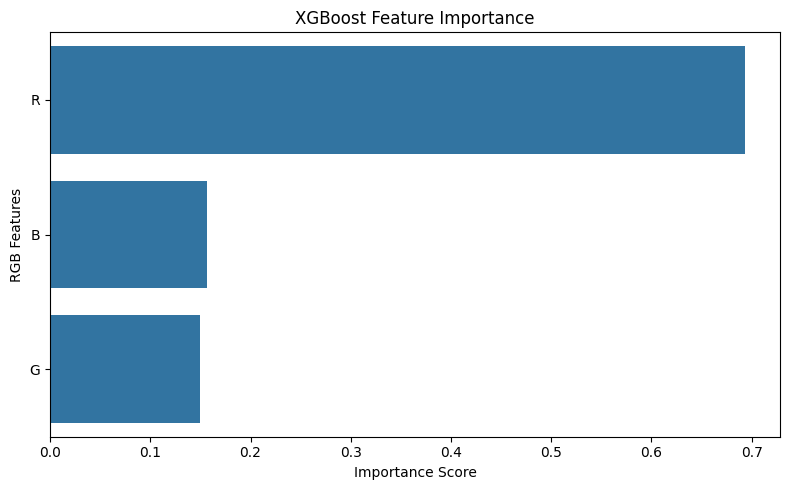

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=xgb_importance,
    x="Importance",
    y="Feature"
)

plt.title("XGBoost Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("RGB Features")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.inspection import permutation_importance

# Random Forest
rf_permutation = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

rf_perm_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": rf_permutation.importances_mean,
    "Std": rf_permutation.importances_std
}).sort_values(
    by="Importance",
    ascending=False
)

display(rf_perm_df)

,Feature,Importance,Std
2,R,0.686273,0.003924
1,G,0.516949,0.003986
0,B,0.480099,0.004922


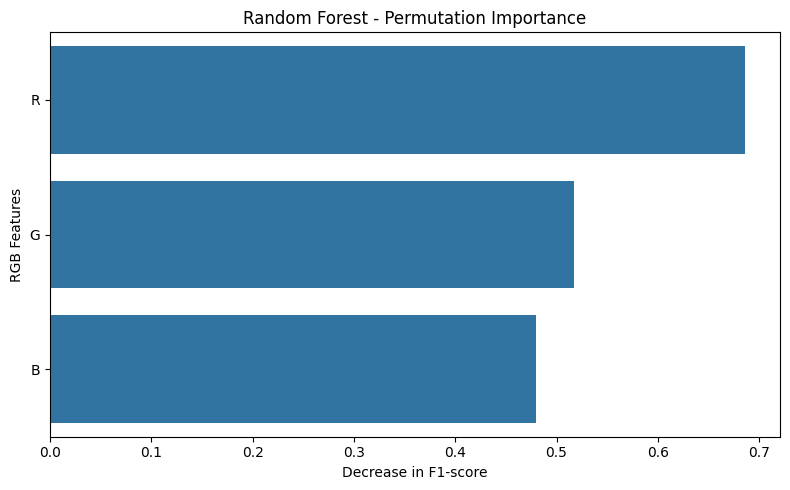

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=rf_perm_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest - Permutation Importance")
plt.xlabel("Decrease in F1-score")
plt.ylabel("RGB Features")

plt.tight_layout()
plt.show()

In [ ]:
xgb_permutation = permutation_importance(
    xgb_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

xgb_perm_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": xgb_permutation.importances_mean,
    "Std": xgb_permutation.importances_std
}).sort_values(
    by="Importance",
    ascending=False
)

display(xgb_perm_df)

,Feature,Importance,Std
2,R,0.659965,0.005115
1,G,0.486974,0.004880
0,B,0.445957,0.003575


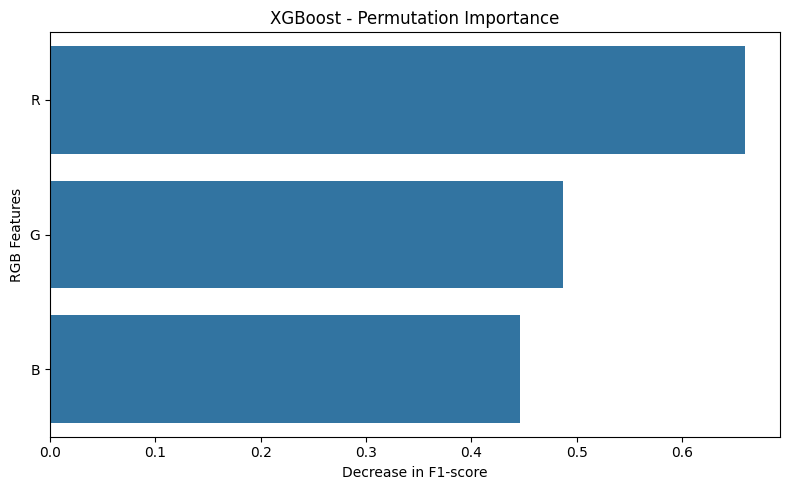

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=xgb_perm_df,
    x="Importance",
    y="Feature"
)

plt.title("XGBoost - Permutation Importance")
plt.xlabel("Decrease in F1-score")
plt.ylabel("RGB Features")

plt.tight_layout()
plt.show()

In [ ]:
feature_comparison = pd.DataFrame({
    "Feature": X_train.columns,

    "RF Tree Importance": rf_model.feature_importances_,

    "XGB Tree Importance": xgb_model.feature_importances_,

    "RF Permutation": rf_permutation.importances_mean,

    "XGB Permutation": xgb_permutation.importances_mean
})

display(feature_comparison.round(6))

,Feature,RF Tree Importance,XGB Tree Importance,RF Permutation,XGB Permutation
0,B,0.218765,0.156738,0.480099,0.445957
1,G,0.234253,0.149719,0.516949,0.486974
2,R,0.546983,0.693543,0.686273,0.659965


In [ ]:
feature_comparison.to_csv(
    "feature_importance_comparison.csv",
    index=False
)

print("Feature importance results saved!")

Feature importance results saved!


final model selection

In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier

from xgboost import XGBClassifier

In [ ]:
final_models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5, n_jobs=1))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=1
    ),

    "Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=1
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearSVC(
            max_iter=20000,
            random_state=42
        ))
    ]),

    "MLP": Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            solver="adam",
            max_iter=200,
            early_stopping=False,
            random_state=42
        ))
    ])
}

In [ ]:
final_cv_results = []

final_scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

for name, model in final_models.items():

    print("\n" + "=" * 55)
    print("Evaluating:", name)
    print("=" * 55)

    start = time.perf_counter()

    scores = cross_validate(
        model,
        X_train,
        y_train,
        groups=groups_train,
        cv=cv,
        scoring=final_scoring,
        n_jobs=-1,
        return_train_score=False
    )

    elapsed = time.perf_counter() - start

    final_cv_results.append({
        "Model": name,

        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),

        "CV F1 Mean": scores["test_f1"].mean(),
        "CV F1 Std": scores["test_f1"].std(),

        "CV ROC-AUC": scores["test_roc_auc"].mean(),

        "CV Time (s)": elapsed
    })

    print("CV F1:", round(scores["test_f1"].mean(), 6))
    print("CV F1 Std:", round(scores["test_f1"].std(), 6))
    print("Time:", round(elapsed, 2), "seconds")


Evaluating: Logistic Regression
CV F1: 0.812398
CV F1 Std: 0.009205
Time: 29.49 seconds

Evaluating: Decision Tree
CV F1: 0.997008
CV F1 Std: 0.000905
Time: 11.88 seconds

Evaluating: KNN
CV F1: 0.998851
CV F1 Std: 0.000185
Time: 14.24 seconds

Evaluating: Random Forest
CV F1: 0.998865
CV F1 Std: 0.000198
Time: 61.99 seconds

Evaluating: Gradient Boosting
CV F1: 0.998623
CV F1 Std: 0.000231
Time: 19.0 seconds

Evaluating: XGBoost
CV F1: 0.998805
CV F1 Std: 0.000267
Time: 18.78 seconds

Evaluating: SVM
CV F1: 0.826511
CV F1 Std: 0.009424
Time: 11.54 seconds

Evaluating: MLP
CV F1: 0.998253
CV F1 Std: 0.000514
Time: 62.14 seconds


In [ ]:
final_cv_df = pd.DataFrame(final_cv_results)

final_cv_df = final_cv_df.sort_values(
    by="CV F1 Mean",
    ascending=False
)

display(final_cv_df.round(6))

,Model,CV Accuracy,CV Precision,CV Recall,CV F1 Mean,CV F1 Std,CV ROC-AUC,CV Time (s)
3,Random Forest,0.999531,0.998045,0.999686,0.998865,0.000198,0.999978,61.991919
2,KNN,0.999524,0.997826,0.999879,0.998851,0.000185,0.999821,14.238019
5,XGBoost,0.999503,0.997978,0.999635,0.998805,0.000267,0.999970,18.782858
4,Gradient Boosting,0.999427,0.997804,0.999443,0.998623,0.000231,0.999955,18.995917
7,MLP,0.999275,0.997110,0.999399,0.998253,0.000514,0.999952,62.136470
1,Decision Tree,0.998764,0.996397,0.997623,0.997008,0.000905,0.998473,11.884770
6,SVM,0.925819,0.798934,0.856176,0.826511,0.009424,0.951016,11.535731
0,Logistic Regression,0.921026,0.797179,0.828363,0.812398,0.009205,0.953803,29.491765


In [ ]:
final_cv_df.to_csv(
    "final_model_selection_cv.csv",
    index=False
)

final model

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import joblib
import seaborn as sns
import matplotlib.pyplot as plt

# Train final selected model
final_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train, y_train)

# Test predictions
final_pred = final_model.predict(X_test)

final_prob = final_model.predict_proba(X_test)[:, 1]

# Evaluation
print("FINAL MODEL: RANDOM FOREST")
print("=" * 45)

print("Accuracy:", accuracy_score(y_test, final_pred))
print("Precision:", precision_score(y_test, final_pred))
print("Recall:", recall_score(y_test, final_pred))
print("F1-score:", f1_score(y_test, final_pred))
print("ROC-AUC:", roc_auc_score(y_test, final_prob))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        final_pred,
        target_names=["Non-skin", "Skin"]
    )
)

FINAL MODEL: RANDOM FOREST
Accuracy: 0.9992408387705691
Precision: 0.9970025140204989
Recall: 0.9994184355917418
F1-score: 0.9982090130209594
ROC-AUC: 0.9999810754300662

Classification Report:
              precision    recall  f1-score   support

    Non-skin       1.00      1.00      1.00     38421
        Skin       1.00      1.00      1.00     10317

    accuracy                           1.00     48738
   macro avg       1.00      1.00      1.00     48738
weighted avg       1.00      1.00      1.00     48738



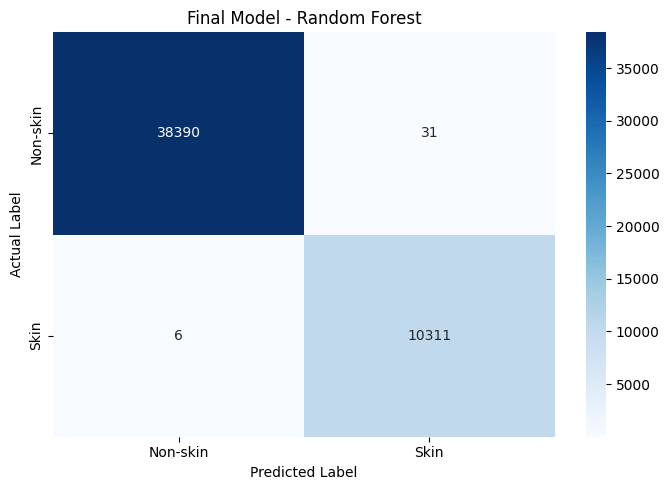

In [ ]:
cm = confusion_matrix(y_test, final_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-skin", "Skin"],
    yticklabels=["Non-skin", "Skin"]
)

plt.title("Final Model - Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [ ]:
joblib.dump(
    final_model,
    "final_skin_segmentation_model.pkl"
)

print("Final Random Forest model saved!")

Final Random Forest model saved!
